# Лабораторная работа 1 по методу обратного распространения ошибки
<h2> Выполнил Прокофьев Кирилл 3825М1ФИ1</h2>

## Import

In [50]:
import numpy as np
import matplotlib.pyplot as plt
import urllib.request
import gzip
import struct
import os
import time

## Data init

In [51]:
url_base = 'https://ossci-datasets.s3.amazonaws.com/mnist/'
files = [
    'train-images-idx3-ubyte.gz',
    'train-labels-idx1-ubyte.gz',
    't10k-images-idx3-ubyte.gz',
    't10k-labels-idx1-ubyte.gz'
]

data_dir = 'mnist_data'
os.makedirs(data_dir, exist_ok=True)

for file in files:
    filepath = os.path.join(data_dir, file)
    if not os.path.exists(filepath):
        print(f"Downloading...")
        urllib.request.urlretrieve(url_base + file, filepath)
        print(f"{file} uploaded.")
    else:
        print(f" {file} already exists.")

def load_mnist_images(filename):
    with gzip.open(filename, 'rb') as f:
        magic, num, rows, cols = struct.unpack('>IIII', f.read(16))
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(num, rows, cols)

def load_mnist_labels(filename):
    with gzip.open(filename, 'rb') as f:
        magic, num = struct.unpack('>II', f.read(8))
        return np.frombuffer(f.read(), dtype=np.uint8)

print("\nReading data...")
X_train_raw = load_mnist_images(os.path.join(data_dir, 'train-images-idx3-ubyte.gz'))
y_train = load_mnist_labels(os.path.join(data_dir, 'train-labels-idx1-ubyte.gz'))
X_test_raw = load_mnist_images(os.path.join(data_dir, 't10k-images-idx3-ubyte.gz'))
y_test = load_mnist_labels(os.path.join(data_dir, 't10k-labels-idx1-ubyte.gz'))

Downloading...
train-images-idx3-ubyte.gz uploaded.
Downloading...
train-labels-idx1-ubyte.gz uploaded.
Downloading...
t10k-images-idx3-ubyte.gz uploaded.
Downloading...
t10k-labels-idx1-ubyte.gz uploaded.

Reading data...


## Preprocessing

In [52]:
#Normalization to the range [0, 1]
X_train = X_train_raw.astype(np.float32) / 255.0
X_test = X_test_raw.astype(np.float32) / 255.0

# Transform (N, 28, 28) into (N, 784) 
X_train = X_train.reshape(-1, 784)  # (60000, 784)
X_test = X_test.reshape(-1, 784)    # (10000, 784)


#Standardization using the mean and std of the MNIST dataset to improve convergence
mean = X_train.mean()
std = X_train.std()
X_train = (X_train - mean) / (std + 1e-8)
X_test = (X_test - mean) / (std + 1e-8)

print(f"X_train shape: {X_train.shape}")  # (60000, 784)
print(f"y_train shape: {y_train.shape}")  # (60000,)
print(f"X_test shape: {X_test.shape}")    # (10000, 784)
print(f"y_test shape: {y_test.shape}")    # (10000,)

X_train shape: (60000, 784)
y_train shape: (60000,)
X_test shape: (10000, 784)
y_test shape: (10000,)


## Displaying images


In [53]:
def ShowImg(X_data, y_data, indices, title="MNIST Samples"):
 
    num_imgs = len(indices)
    cols = min(10, num_imgs)
    rows = (num_imgs + cols - 1) // cols
    
    figsize = (cols * 1.5, rows * 1.5)
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    fig.suptitle(title, fontsize=14)
    
    if rows == 1 and cols == 1:
        axes = np.array([axes])
    axes = np.array(axes).flatten()
    
    for i, ax in enumerate(axes):
        if i >= num_imgs:
            ax.axis('off')
            continue
            
        idx = indices[i]
    #Reshaping from a flat vector (784,) to the shape (28, 28)
        img = X_data[idx].reshape(28, 28)
        label = y_data[idx]
        
        ax.imshow(img, cmap='gray')
        ax.set_title(f"Label: {label}", fontsize=10)
        ax.axis('off')
    
    plt.tight_layout()
    plt.show()


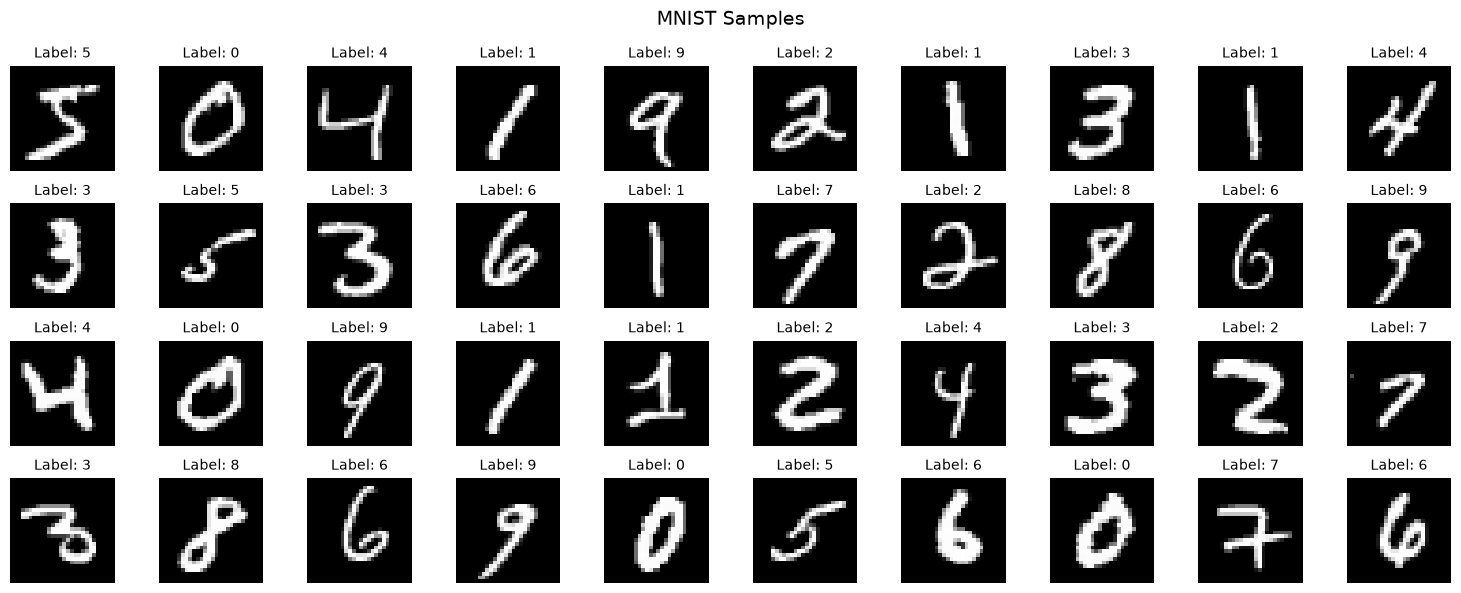

In [54]:
ShowImg(X_train, y_train, indices=list(range(40)), title="MNIST Samples")

# Main Functions

In [55]:
def initialize_parameters():
    input_size = 784
    hidden_size = 300
    output_size = 10
    
    W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2.0 / input_size)
    b1 = np.zeros((1, hidden_size))
    W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2.0 / hidden_size)
    b2 = np.zeros((1, output_size))
    
    return {"W1": W1, "b1": b1, "W2": W2, "b2": b2}

def relu(x):
    return np.maximum(0, x)

def relu_derivative(x):
    return (x > 0).astype(float)

def softmax(x):
    exp_x = np.exp(x - np.max(x, axis=1, keepdims=True))
    return exp_x / np.sum(exp_x, axis=1, keepdims=True)

def forward(X, params):
    W1, b1, W2, b2 = params["W1"], params["b1"], params["W2"], params["b2"]
    
    f = np.dot(X, W1) + b1      
    v = relu(f)               
    g = np.dot(v, W2) + b2    
    u = softmax(g)             
    
    cache = {"f": f, "v": v, "g": g, "u": u}
    return u, cache

def one_hot_encode(y, num_classes=10):
    y_encoded = np.zeros((y.size, num_classes))
    y_encoded[np.arange(y.size), y] = 1
    return y_encoded

def backward(X, y_true, params, cache):
    L = X.shape[0]
    W2 = params["W2"]
    v, u, f = cache["v"], cache["u"], cache["f"]

    d_g = u - y_true  
    d_W2 = np.dot(v.T, d_g) / L
    d_b2 = np.sum(d_g, axis=0, keepdims=True) / L
    
    d_v = np.dot(d_g, W2.T)
    d_f = d_v * relu_derivative(f) / L 
    d_W1 = np.dot(X.T, d_f) 
    d_b1 = np.sum(d_f, axis=0, keepdims=True) / L
    
    return {"W1": d_W1, "b1": d_b1, "W2": d_W2, "b2": d_b2}

def update_parameters(params, grads, learning_rate):
    for key in params:
        params[key] -= learning_rate * grads[key]
    return params

def classification_error(y_pred, y_true):
    predictions = np.argmax(y_pred, axis=1)
    return np.mean(predictions != y_true)

def train(X_train, y_train, X_val, y_val, parameters, 
                 epochs=20, batch_size=64, learning_rate=0.1):
    
    y_train_oh = one_hot_encode(y_train)
    n_train = X_train.shape[0]
    
    for epoch in range(epochs):
        start_time = time.time()
        
        index = np.random.permutation(n_train)
        X_mix = X_train[index]
        y_mix_oh = y_train_oh[index]
        y_mix = y_train[index]
        
        epoch_correct = 0
        
        for i in range(0, n_train, batch_size):
            X_batch = X_mix[i:i+batch_size]
            y_batch_oh = y_mix_oh[i:i+batch_size]
            y_batch = y_mix[i:i+batch_size]
            
            y_pred, cache = forward(X_batch, parameters)
            
            predictions = np.argmax(y_pred, axis=1)
            epoch_correct += np.sum(predictions == y_batch)
  
            grads = backward(X_batch, y_batch_oh, parameters, cache)
            parameters = update_parameters(parameters, grads, learning_rate)
        
        train_accuracy = epoch_correct / n_train
        train_error = 1 - train_accuracy
        
        y_val_pred, _ = forward(X_val, parameters)
        val_error = classification_error(y_val_pred, y_val)
                
        epoch_time = time.time() - start_time
        
        print(f"Epoch {epoch+1:2d}/{epochs} | "
              f"Train error: {train_error:.4f} | "
              f"Val error: {val_error:.4f} | "
              f"Time: {epoch_time:.2f}s")
    
    return parameters

# Model training

In [56]:
parameters = initialize_parameters()

trained_params = train(
    X_train, y_train,
    X_test, y_test,  
    parameters,
    epochs=20,
    batch_size=64,
    learning_rate=0.1
)

Epoch  1/20 | Train error: 0.0670 | Val error: 0.0392 | Time: 0.89s
Epoch  2/20 | Train error: 0.0280 | Val error: 0.0305 | Time: 1.09s
Epoch  3/20 | Train error: 0.0184 | Val error: 0.0237 | Time: 1.15s
Epoch  4/20 | Train error: 0.0129 | Val error: 0.0223 | Time: 1.12s
Epoch  5/20 | Train error: 0.0093 | Val error: 0.0251 | Time: 0.86s
Epoch  6/20 | Train error: 0.0063 | Val error: 0.0244 | Time: 0.86s
Epoch  7/20 | Train error: 0.0045 | Val error: 0.0201 | Time: 1.09s
Epoch  8/20 | Train error: 0.0025 | Val error: 0.0211 | Time: 1.00s
Epoch  9/20 | Train error: 0.0014 | Val error: 0.0193 | Time: 0.88s
Epoch 10/20 | Train error: 0.0009 | Val error: 0.0219 | Time: 1.42s
Epoch 11/20 | Train error: 0.0006 | Val error: 0.0196 | Time: 1.14s
Epoch 12/20 | Train error: 0.0003 | Val error: 0.0194 | Time: 1.42s
Epoch 13/20 | Train error: 0.0001 | Val error: 0.0189 | Time: 1.56s
Epoch 14/20 | Train error: 0.0002 | Val error: 0.0185 | Time: 1.98s
Epoch 15/20 | Train error: 0.0001 | Val error: 0

# Final error in the test and accuracy

In [57]:
y_test_pred, _ = forward(X_test, trained_params)
test_error = classification_error(y_test_pred, y_test)
print(f"\nFinal error in the test: {test_error:.4f}")
print(f"Accuracy : {(1 - test_error) * 100:.2f}%")


Final error in the test: 0.0185
Accuracy : 98.15%


# Predictions

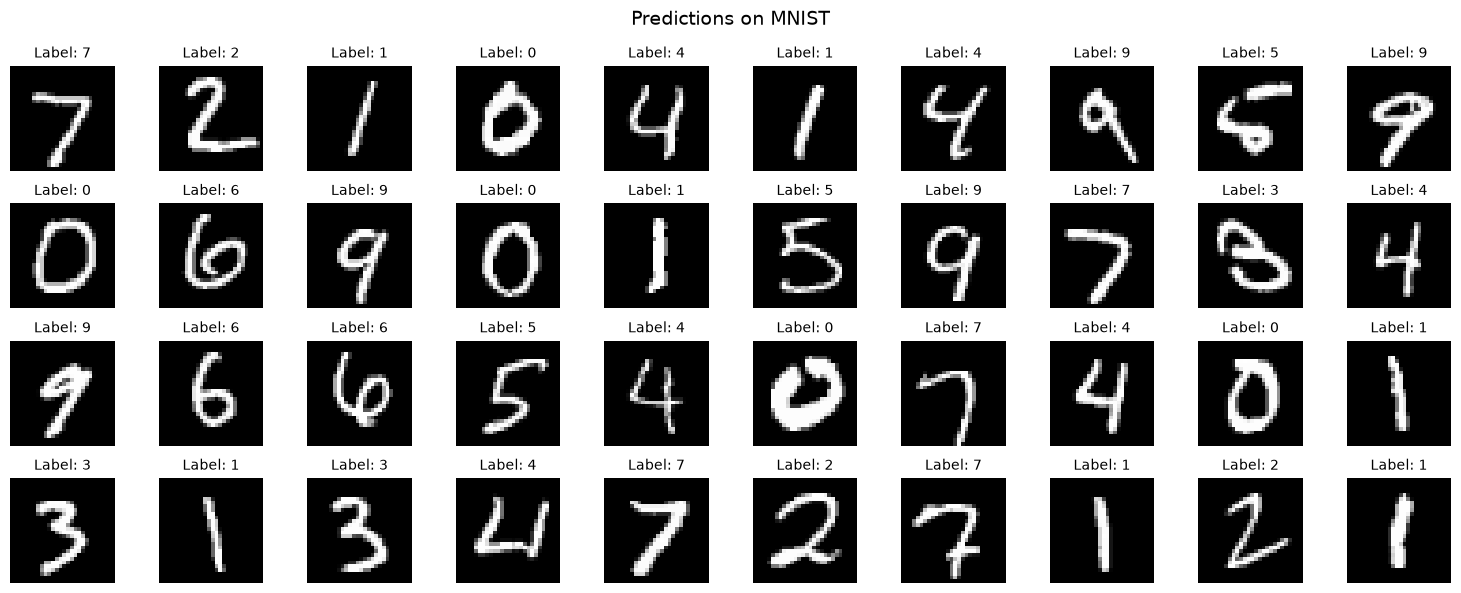

In [58]:
ShowImg(X_test, y_test, indices=list(range(40)), title="Predictions on MNIST")